<div align="center"> 

---



# **Cerebellum Mega Analysis**


<img src="https://static.wixstatic.com/media/da4857_5f6dbdb6bbd84328b1e31c7f2dafb673~mv2.png/v1/fill/w_224,h_226,al_c,q_85,usm_0.66_1.00_0.01,enc_auto/enigma_addiction-300x249.png" alt="image" style="width:300px;"/>


 </img>
</div>

---
# <u> **Project Description:**</u>

## **Sensitivity Analysis: Permutation Tests for Complete-Cases (CC) and Alternative-Imputation (AI) Datasets**

This notebook performs **permutation-based** cross-validated sensitivity analyses on:

- **CC** — Complete-Cases: subjects with fully observed Age and Sex (no imputation needed)
- **AI** — Alternative Imputation: Age and Sex imputed using Substance group and Site only  
  (no neuroanatomical predictors, avoiding potential circularity)

1. Fit a linear model (volume ~ group, HC as reference)
2. Extract the observed t-statistic per region
3. Build a null distribution via bootstrap resampling (1000 permutations)
4. Compute permutation p-values and apply FDR correction

**Atlases covered:** Acapulco + MDTB  
**Contrasts:** User vs HC, Substance vs HC

---

In [1]:
addTaskCallback(function(...) {set.seed(42);TRUE})
options(warn=-1) # to turn off warnings
#options(warn=0) # to turn on warnings
options(repr.plot.width=10, repr.plot.height=6) # to resize plots

1 
1

In [2]:
setwd("/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum/")

## Load Packages

In [3]:
# Load required packages  
pacman::p_load(tidyverse, devtools, readxl, VIM, mice, vtreat, sjmisc,
               broom, janitor, tidyr, reshape2, caret, tidymodels,
               foreach, doParallel, emmeans)

# NeuroCombat
if (!require("neuroCombat")) {
  devtools::install_github("jfortin1/neuroCombat_Rpackage")
}
library(neuroCombat)

Loading required package: neuroCombat



## Global settings

In [4]:
# Number of permutations (same as primary analyses)
num_perm <- 1000

`%notin%` <- Negate(`%in%`)

# Output directories
dir.create("Statistics/Sanity_check/Acapulco", recursive = TRUE, showWarnings = FALSE)
dir.create("Statistics/Sanity_check/MDTB",    recursive = TRUE, showWarnings = FALSE)

## Load data

In [5]:
# Load harmonised CC / AI volumes for both atlases
load("Data/RData/Sanity_check/Volumes_Cerebellum_Sanity_check.RData")
ls()

[1] "%notin%"                                  
 [2] "num_perm"                                 
 [3] "Volumes_Cerebellum_Acapulco_Harmonized_AI"
 [4] "Volumes_Cerebellum_Acapulco_Harmonized_CC"
 [5] "Volumes_Cerebellum_Acapulco_raw_AI"       
 [6] "Volumes_Cerebellum_Acapulco_raw_CC"       
 [7] "Volumes_Cerebellum_MDTB_Harmonized_AI"    
 [8] "Volumes_Cerebellum_MDTB_Harmonized_CC"    
 [9] "Volumes_Cerebral_DK_Harmonized_AI"        
[10] "Volumes_Cerebral_DK_Harmonized_CC"

---
# **Part 1 — Acapulco Atlas**

## **1.1 Prepare Acapulco CC and AI datasets**

In [6]:
# Helper: bring CC / AI Acapulco volumes into analysis shape
prepare_acapulco_sc <- function(harmonized_df) {
    harmonized_df %>%
        filter(Substance != "OPI") %>%
        mutate(
            group     = factor(if_else(Substance == "HC", 0, 1), labels = c("HC", "User")),
            Substance = factor(Substance, levels = c("ALC", "ATS", "CANN", "COC", "NIC", "HC"))
        ) %>%
        mutate(group = factor(group, levels = c("User", "HC"))) %>%
        mutate(
            Database = factor(Database),
            GM_Vol   = Total_Cerebel_Vol - Corpus.Medullare
        )
}

Acapulco_volumes_CC <- prepare_acapulco_sc(Volumes_Cerebellum_Acapulco_Harmonized_CC)
Acapulco_volumes_AI <- prepare_acapulco_sc(Volumes_Cerebellum_Acapulco_Harmonized_AI)

# Region name vector (same set used in primary analyses)
Acapulco_cerebellar_regions_names <- Acapulco_volumes_CC %>%
    select(contains(c(".", "_Vol"))) %>% colnames()

# Long format
Acapulco_volumes_long_CC <- Acapulco_volumes_CC %>%
    pivot_longer(names_to = "region", values_to = "volume",
                 all_of(Acapulco_cerebellar_regions_names)) %>%
    arrange(region) %>%
    mutate(region = factor(region, levels = unique(.$region)))

Acapulco_volumes_long_AI <- Acapulco_volumes_AI %>%
    pivot_longer(names_to = "region", values_to = "volume",
                 all_of(Acapulco_cerebellar_regions_names)) %>%
    arrange(region) %>%
    mutate(region = factor(region, levels = unique(.$region)))

substances_names_Acapulco <- unique(Acapulco_volumes_CC$Substance)[
    unique(Acapulco_volumes_CC$Substance) != "HC"] %>% as.vector()

cat("Acapulco CC dataset:", nrow(Acapulco_volumes_CC), "subjects\n")
cat("Acapulco AI dataset:", nrow(Acapulco_volumes_AI), "subjects\n")
cat("Regions:", length(Acapulco_cerebellar_regions_names), "\n")
cat("Substances:", paste(substances_names_Acapulco, collapse = ", "), "\n")

Acapulco CC dataset: 2933 subjects
Acapulco AI dataset: 3461 subjects
Regions: 30 
Substances: ALC, ATS, CANN, COC, NIC 


## **1.2 Acapulco — CC Permutation Analysis**

### **1.2.1 User vs HC (CC)**

#### Running the linear model

In [7]:
Acapulco_lm_CC_user_vs_control <- Acapulco_volumes_long_CC %>%
    select(group, region, volume) %>%
    nest(data = -region) %>%
    mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
    mutate(test = map(data, ~ {
        m   <- lm(volume ~ group, data = .)
        dat <- broom::tidy(m, conf.int = TRUE) %>%
            filter(term == "groupUser") %>%
            mutate(df = df.residual(m), sigma = sigma(m))
        cont      <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
        cohen_d   <- broom::tidy(cont)$estimate / sigma(m)
        dat %>% mutate(effect.size = cohen_d)
    })) %>%
    unnest(test)

#### Build null distributions

In [8]:
if (!exists("Acapulco_nulls_CC_user_vs_control")) {
    Acapulco_nulls_CC_user_vs_control <- matrix(
        NA_real_,
        nrow = num_perm,
        ncol = length(Acapulco_cerebellar_regions_names)
    )
}

In [9]:
Acapulco_compute_null_CC_user <- function(df, regions, nulls_mat, num_perm) {
    if (sum(is.na(nulls_mat)) == 0) return(nulls_mat)

    cl <- parallel::makeCluster(max(1, parallel::detectCores() - 1))
    on.exit(parallel::stopCluster(cl), add = TRUE)
    doParallel::registerDoParallel(cl)

    res <- foreach(
        i          = seq_len(num_perm),
        .packages  = c("dplyr", "tidyr", "purrr", "broom"),
        .export    = c("regions")
    ) %dopar% {
        set.seed(42 + i)
        boot <- sample.int(nrow(df), replace = TRUE)

        dplyr::bind_cols(
            data.frame(group = df$group[boot], check.names = FALSE),
            dplyr::select(df, dplyr::all_of(regions))
        ) %>%
            dplyr::mutate(group = stats::relevel(as.factor(group), ref = "HC")) %>%
            tidyr::pivot_longer(cols = dplyr::all_of(regions),
                                names_to = "region", values_to = "volume") %>%
            tidyr::nest(data = -region) %>%
            dplyr::mutate(test = purrr::map(data, ~ {
                m <- lm(volume ~ group, data = .x)
                broom::tidy(m) %>%
                    dplyr::filter(term == "groupUser") %>%
                    dplyr::select(statistic)
            })) %>%
            tidyr::unnest(test) %>%
            dplyr::pull(statistic)
    }

    for (j in seq_len(num_perm)) nulls_mat[j, ] <- res[[j]]
    return(nulls_mat)
}

#### Perform permutation and save

In [10]:
nulls_fp_CC_user_Acapulco <- file.path(
    "Statistics", "Sanity_check", "Acapulco",
    "Acapulco_nulls_CC_user_vs_control.RData"
)

if (!file.exists(nulls_fp_CC_user_Acapulco)) {

    Acapulco_nulls_CC_user_vs_control <- Acapulco_compute_null_CC_user(
        Acapulco_volumes_CC, Acapulco_cerebellar_regions_names,
        Acapulco_nulls_CC_user_vs_control, num_perm
    )
    colnames(Acapulco_nulls_CC_user_vs_control) <- as.character(
        Acapulco_lm_CC_user_vs_control$region
    )

    ci_lower <- apply(Acapulco_nulls_CC_user_vs_control, 2, quantile, probs = 0.025)
    ci_upper <- apply(Acapulco_nulls_CC_user_vs_control, 2, quantile, probs = 0.975)

    pvals <- purrr::map2_dbl(
        as.data.frame(Acapulco_nulls_CC_user_vs_control),
        Acapulco_lm_CC_user_vs_control$statistic,
        ~ mean(abs(.x) >= abs(.y))
    )

    p_values_Acapulco_CC_user_vs_control_perm <- Acapulco_lm_CC_user_vs_control %>%
        select(-data) %>%
        mutate(
            p.value       = pvals,
            perm_CI_lower = ci_lower[as.character(region)],
            perm_CI_upper = ci_upper[as.character(region)],
            p.adj         = p.adjust(p.value, method = "fdr")
        )

    save(Acapulco_nulls_CC_user_vs_control,
         p_values_Acapulco_CC_user_vs_control_perm,
         file = nulls_fp_CC_user_Acapulco)
    cat("Saved:", nulls_fp_CC_user_Acapulco, "\n")

} else {
    load(nulls_fp_CC_user_Acapulco)
    cat("Loaded:", nulls_fp_CC_user_Acapulco, "\n")
}

p_values_Acapulco_CC_user_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/Acapulco/Acapulco_nulls_CC_user_vs_control.RData 
# A tibble: 2 × 5
  region           statistic effect.size p.value p.adj
  <fct>                <dbl>       <dbl>   <dbl> <dbl>
1 Corpus.Medullare      3.72      -0.140   0     0    
2 Right.VIIB           -3.62       0.137   0.001 0.015


### **1.2.2 Substance vs HC (CC)**

#### Running the linear models

In [11]:
Acapulco_lm_CC_substance_vs_control <- map_df(substances_names_Acapulco, .f = ~ {
    Acapulco_volumes_long_CC %>%
        filter(Substance %in% c("HC", .x)) %>%
        select(group, region, volume) %>%
        nest(data = -region) %>%
        mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
        mutate(test = map(data, ~ {
            m   <- lm(volume ~ group, data = .)
            dat <- broom::tidy(m, conf.int = TRUE) %>%
                filter(term == "groupUser") %>%
                mutate(df = df.residual(m), sigma = sigma(m))
            cont    <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
            cohen_d <- broom::tidy(cont)$estimate / sigma(m)
            dat %>% mutate(effect.size = cohen_d)
        })) %>%
        unnest(test) %>%
        mutate(Substance = .x)
})

#### Build null distributions

In [12]:
if (!exists("Acapulco_nulls_CC_substance_vs_control")) {
    Acapulco_nulls_CC_substance_vs_control <- lapply(
        seq_along(substances_names_Acapulco),
        function(i) matrix(NA_real_, nrow = num_perm,
                           ncol = length(Acapulco_cerebellar_regions_names))
    ) %>% setNames(substances_names_Acapulco)
}

In [13]:
Acapulco_compute_null_CC_substances <- function(volumes_df, regions, subst_names,
                                                nulls_list, num_perm) {
    if (sum(is.na(unlist(nulls_list))) == 0) return(nulls_list)

    cl <- parallel::makeCluster(max(1, parallel::detectCores() - 1))
    on.exit(parallel::stopCluster(cl), add = TRUE)
    doParallel::registerDoParallel(cl)

    res <- foreach(
        i         = seq_along(subst_names),
        .packages = c("dplyr", "tidyr", "purrr", "broom")
    ) %dopar% {
        current <- nulls_list[[i]]
        if (!is.null(current) && sum(is.na(current)) == 0) return(current)

        set.seed(42 + i)
        sub_df <- volumes_df %>%
            dplyr::filter(Substance %in% c("HC", subst_names[i])) %>%
            dplyr::select(group, dplyr::all_of(regions))

        nulls <- matrix(NA_real_, nrow = num_perm, ncol = length(regions))

        for (j in seq_len(num_perm)) {
            set.seed(42 + i + j)
            boot <- sample.int(nrow(sub_df), replace = TRUE)

            nulls[j, ] <- dplyr::bind_cols(
                data.frame(group = sub_df$group[boot], check.names = FALSE),
                dplyr::select(sub_df, dplyr::all_of(regions))
            ) %>%
                dplyr::mutate(group = stats::relevel(as.factor(group), ref = "HC")) %>%
                tidyr::pivot_longer(cols = dplyr::all_of(regions),
                                    names_to = "region", values_to = "volume") %>%
                tidyr::nest(data = -region) %>%
                dplyr::mutate(test = purrr::map(data, ~ {
                    m <- lm(volume ~ group, data = .x)
                    broom::tidy(m) %>%
                        dplyr::filter(term == "groupUser") %>%
                        dplyr::select(statistic)
                })) %>%
                tidyr::unnest(test) %>%
                dplyr::pull(statistic)
        }
        nulls
    } %>% rlang::set_names(subst_names)

    return(res)
}

#### Perform permutation and save

In [14]:
nulls_fp_CC_subst_Acapulco <- file.path(
    "Statistics", "Sanity_check", "Acapulco",
    "Acapulco_nulls_CC_substance_vs_control.RData"
)

if (!file.exists(nulls_fp_CC_subst_Acapulco)) {

    Acapulco_nulls_CC_substance_vs_control <- Acapulco_compute_null_CC_substances(
        Acapulco_volumes_CC, Acapulco_cerebellar_regions_names,
        substances_names_Acapulco, Acapulco_nulls_CC_substance_vs_control, num_perm
    )
    Acapulco_nulls_CC_substance_vs_control <- purrr::imap(
        Acapulco_nulls_CC_substance_vs_control,
        ~ { colnames(.x) <- Acapulco_cerebellar_regions_names; .x }
    )

    Acapulco_CC_subst_CIs <- purrr::imap_dfr(
        Acapulco_nulls_CC_substance_vs_control,
        ~ tibble(
            Substance     = .y,
            region        = colnames(.x),
            perm_CI_lower = apply(.x, 2, quantile, probs = 0.025),
            perm_CI_upper = apply(.x, 2, quantile, probs = 0.975)
        )
    )

    p_values_Acapulco_CC_substance_vs_control_perm <- Acapulco_lm_CC_substance_vs_control %>%
        select(-data) %>%
        mutate(
            p.value = purrr::pmap_dbl(
                list(Substance, as.character(region), statistic),
                function(substance, roi, stat) {
                    null_dist <- Acapulco_nulls_CC_substance_vs_control[[substance]][, roi]
                    mean(abs(null_dist) >= abs(stat))
                }
            )
        ) %>%
        group_by(Substance) %>%
        mutate(p.adj = p.adjust(p.value, method = "fdr")) %>%
        ungroup() %>%
        left_join(Acapulco_CC_subst_CIs, by = c("Substance", "region"))

    save(Acapulco_nulls_CC_substance_vs_control,
         Acapulco_CC_subst_CIs,
         p_values_Acapulco_CC_substance_vs_control_perm,
         file = nulls_fp_CC_subst_Acapulco)
    cat("Saved:", nulls_fp_CC_subst_Acapulco, "\n")

} else {
    load(nulls_fp_CC_subst_Acapulco)
    cat("Loaded:", nulls_fp_CC_subst_Acapulco, "\n")
}

p_values_Acapulco_CC_substance_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(Substance, region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/Acapulco/Acapulco_nulls_CC_substance_vs_control.RData 
# A tibble: 19 × 6
   Substance region            statistic effect.size p.value  p.adj
   <chr>     <chr>                 <dbl>       <dbl>   <dbl>  <dbl>
 1 ALC       GM_Vol                -3.77       0.204   0     0     
 2 ALC       Left.Crus.I           -4.36       0.237   0     0     
 3 ALC       Left.I.III            -2.56       0.138   0.009 0.03  
 4 ALC       Left.V                -3.79       0.205   0     0     
 5 ALC       Left.VIIIA             2.75      -0.149   0.004 0.015 
 6 ALC       Right.Crus.I          -4.14       0.225   0     0     
 7 ALC       Right.V               -3.65       0.199   0     0     
 8 ALC       Right.VIIB            -3.97       0.215   0     0     
 9 ALC       Rigt.IV               -2.44       0.132   0.016 0.048 
10 ALC       Total_Cerebel_Vol     -3.20       0.173   0.003 0.0129
11 COC       Corpus.Medullare       4.65      -0.271   0     0     
12 COC     

## **1.3 Acapulco — AI Permutation Analysis**

### **1.3.1 User vs HC (AI)**

#### Running the linear model

In [15]:
Acapulco_lm_AI_user_vs_control <- Acapulco_volumes_long_AI %>%
    select(group, region, volume) %>%
    nest(data = -region) %>%
    mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
    mutate(test = map(data, ~ {
        m   <- lm(volume ~ group, data = .)
        dat <- broom::tidy(m, conf.int = TRUE) %>%
            filter(term == "groupUser") %>%
            mutate(df = df.residual(m), sigma = sigma(m))
        cont    <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
        cohen_d <- broom::tidy(cont)$estimate / sigma(m)
        dat %>% mutate(effect.size = cohen_d)
    })) %>%
    unnest(test)

#### Build null distributions

In [16]:
if (!exists("Acapulco_nulls_AI_user_vs_control")) {
    Acapulco_nulls_AI_user_vs_control <- matrix(
        NA_real_,
        nrow = num_perm,
        ncol = length(Acapulco_cerebellar_regions_names)
    )
}

#### Perform permutation and save

In [17]:
nulls_fp_AI_user_Acapulco <- file.path(
    "Statistics", "Sanity_check", "Acapulco",
    "Acapulco_nulls_AI_user_vs_control.RData"
)

if (!file.exists(nulls_fp_AI_user_Acapulco)) {

    Acapulco_nulls_AI_user_vs_control <- Acapulco_compute_null_CC_user(
        Acapulco_volumes_AI, Acapulco_cerebellar_regions_names,
        Acapulco_nulls_AI_user_vs_control, num_perm
    )
    colnames(Acapulco_nulls_AI_user_vs_control) <- as.character(
        Acapulco_lm_AI_user_vs_control$region
    )

    ci_lower <- apply(Acapulco_nulls_AI_user_vs_control, 2, quantile, probs = 0.025)
    ci_upper <- apply(Acapulco_nulls_AI_user_vs_control, 2, quantile, probs = 0.975)

    pvals <- purrr::map2_dbl(
        as.data.frame(Acapulco_nulls_AI_user_vs_control),
        Acapulco_lm_AI_user_vs_control$statistic,
        ~ mean(abs(.x) >= abs(.y))
    )

    p_values_Acapulco_AI_user_vs_control_perm <- Acapulco_lm_AI_user_vs_control %>%
        select(-data) %>%
        mutate(
            p.value       = pvals,
            perm_CI_lower = ci_lower[as.character(region)],
            perm_CI_upper = ci_upper[as.character(region)],
            p.adj         = p.adjust(p.value, method = "fdr")
        )

    save(Acapulco_nulls_AI_user_vs_control,
         p_values_Acapulco_AI_user_vs_control_perm,
         file = nulls_fp_AI_user_Acapulco)
    cat("Saved:", nulls_fp_AI_user_Acapulco, "\n")

} else {
    load(nulls_fp_AI_user_Acapulco)
    cat("Loaded:", nulls_fp_AI_user_Acapulco, "\n")
}

p_values_Acapulco_AI_user_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/Acapulco/Acapulco_nulls_AI_user_vs_control.RData 
# A tibble: 15 × 5
   region            statistic effect.size p.value   p.adj
   <fct>                 <dbl>       <dbl>   <dbl>   <dbl>
 1 Corpus.Medullare       6.32     -0.227    0     0      
 2 GM_Vol                -3.52      0.126    0     0      
 3 Left.Crus.I           -2.50      0.0899   0.011 0.0236 
 4 Left.I.III            -4.29      0.154    0     0      
 5 Left.V                -5.45      0.196    0     0      
 6 Left.VIIIA             3.19     -0.115    0     0      
 7 Left.VIIIB            -2.45      0.0882   0.01  0.0231 
 8 Right.I.III           -3.84      0.138    0     0      
 9 Right.V               -3.35      0.122    0     0      
10 Right.VI              -3.36      0.122    0.001 0.00273
11 Right.VIIB            -4.45      0.160    0     0      
12 Right.VIIIA            3.73     -0.135    0     0      
13 Right.VIIIB           -2.91      0.105    0.005 0.0125 
14 Rigt.IV     

### **1.3.2 Substance vs HC (AI)**

#### Running the linear models

In [18]:
substances_names_Acapulco_AI <- unique(Acapulco_volumes_AI$Substance)[
    unique(Acapulco_volumes_AI$Substance) != "HC"] %>% as.vector()

Acapulco_lm_AI_substance_vs_control <- map_df(substances_names_Acapulco_AI, .f = ~ {
    Acapulco_volumes_long_AI %>%
        filter(Substance %in% c("HC", .x)) %>%
        select(group, region, volume) %>%
        nest(data = -region) %>%
        mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
        mutate(test = map(data, ~ {
            m   <- lm(volume ~ group, data = .)
            dat <- broom::tidy(m, conf.int = TRUE) %>%
                filter(term == "groupUser") %>%
                mutate(df = df.residual(m), sigma = sigma(m))
            cont    <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
            cohen_d <- broom::tidy(cont)$estimate / sigma(m)
            dat %>% mutate(effect.size = cohen_d)
        })) %>%
        unnest(test) %>%
        mutate(Substance = .x)
})

#### Build null distributions

In [19]:
if (!exists("Acapulco_nulls_AI_substance_vs_control")) {
    Acapulco_nulls_AI_substance_vs_control <- lapply(
        seq_along(substances_names_Acapulco_AI),
        function(i) matrix(NA_real_, nrow = num_perm,
                           ncol = length(Acapulco_cerebellar_regions_names))
    ) %>% setNames(substances_names_Acapulco_AI)
}

#### Perform permutation and save

In [20]:
nulls_fp_AI_subst_Acapulco <- file.path(
    "Statistics", "Sanity_check", "Acapulco",
    "Acapulco_nulls_AI_substance_vs_control.RData"
)

if (!file.exists(nulls_fp_AI_subst_Acapulco)) {

    Acapulco_nulls_AI_substance_vs_control <- Acapulco_compute_null_CC_substances(
        Acapulco_volumes_AI, Acapulco_cerebellar_regions_names,
        substances_names_Acapulco_AI, Acapulco_nulls_AI_substance_vs_control, num_perm
    )
    Acapulco_nulls_AI_substance_vs_control <- purrr::imap(
        Acapulco_nulls_AI_substance_vs_control,
        ~ { colnames(.x) <- Acapulco_cerebellar_regions_names; .x }
    )

    Acapulco_AI_subst_CIs <- purrr::imap_dfr(
        Acapulco_nulls_AI_substance_vs_control,
        ~ tibble(
            Substance     = .y,
            region        = colnames(.x),
            perm_CI_lower = apply(.x, 2, quantile, probs = 0.025),
            perm_CI_upper = apply(.x, 2, quantile, probs = 0.975)
        )
    )

    p_values_Acapulco_AI_substance_vs_control_perm <- Acapulco_lm_AI_substance_vs_control %>%
        select(-data) %>%
        mutate(
            p.value = purrr::pmap_dbl(
                list(Substance, as.character(region), statistic),
                function(substance, roi, stat) {
                    null_dist <- Acapulco_nulls_AI_substance_vs_control[[substance]][, roi]
                    mean(abs(null_dist) >= abs(stat))
                }
            )
        ) %>%
        group_by(Substance) %>%
        mutate(p.adj = p.adjust(p.value, method = "fdr")) %>%
        ungroup() %>%
        left_join(Acapulco_AI_subst_CIs, by = c("Substance", "region"))

    save(Acapulco_nulls_AI_substance_vs_control,
         Acapulco_AI_subst_CIs,
         p_values_Acapulco_AI_substance_vs_control_perm,
         file = nulls_fp_AI_subst_Acapulco)
    cat("Saved:", nulls_fp_AI_subst_Acapulco, "\n")

} else {
    load(nulls_fp_AI_subst_Acapulco)
    cat("Loaded:", nulls_fp_AI_subst_Acapulco, "\n")
}

p_values_Acapulco_AI_substance_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(Substance, region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/Acapulco/Acapulco_nulls_AI_substance_vs_control.RData 
# A tibble: 33 × 6
   Substance region            statistic effect.size p.value   p.adj
   <chr>     <chr>                 <dbl>       <dbl>   <dbl>   <dbl>
 1 ALC       Corpus.Medullare       6.71     -0.296    0     0      
 2 ALC       GM_Vol                -6.61      0.292    0     0      
 3 ALC       Left.Crus.I           -6.12      0.271    0     0      
 4 ALC       Left.I.III            -6.38      0.282    0     0      
 5 ALC       Left.V                -8.23      0.363    0     0      
 6 ALC       Left.VI               -2.83      0.126    0.006 0.00947
 7 ALC       Left.VIIIA             4.95     -0.219    0     0      
 8 ALC       Left.VIIIB            -2.88      0.127    0.005 0.00833
 9 ALC       Right.Crus.I          -5.43      0.240    0     0      
10 ALC       Right.I.III           -6.29      0.277    0     0      
11 ALC       Right.V               -7.30      0.328    0     0     

## **1.4 Save consolidated Acapulco permutation sanity-check results**

In [21]:
sc_perm_fp_Acapulco <- "Statistics/Sanity_check/Acapulco/Acapulco_sanity_check_perm_statistics.RData"

save(
    p_values_Acapulco_CC_user_vs_control_perm,
    p_values_Acapulco_CC_substance_vs_control_perm,
    p_values_Acapulco_AI_user_vs_control_perm,
    p_values_Acapulco_AI_substance_vs_control_perm,
    file = sc_perm_fp_Acapulco
)
cat("Consolidated Acapulco permutation results saved.\n")

# Export CSV summaries
purrr::iwalk(
    list(
        Acapulco_CC_user_vs_control_perm       = p_values_Acapulco_CC_user_vs_control_perm,
        Acapulco_CC_substance_vs_control_perm  = p_values_Acapulco_CC_substance_vs_control_perm,
        Acapulco_AI_user_vs_control_perm       = p_values_Acapulco_AI_user_vs_control_perm,
        Acapulco_AI_substance_vs_control_perm  = p_values_Acapulco_AI_substance_vs_control_perm
    ),
    ~ write_csv(.x, file.path("Statistics", "Sanity_check", "Acapulco",
                               paste0(.y, ".csv")))
)
cat("CSVs written.\n")

Consolidated Acapulco permutation results saved.
CSVs written.


---
# **Part 2 — MDTB Atlas**

## **2.1 Prepare MDTB CC and AI datasets**

In [22]:
# Helper: bring CC / AI MDTB volumes into analysis shape
prepare_mdtb_sc <- function(harmonized_df) {
    harmonized_df %>%
        filter(Substance != "OPI") %>%
        mutate(
            group     = factor(if_else(Substance == "HC", 0, 1), labels = c("HC", "User")),
            Substance = factor(Substance, levels = c("ALC", "ATS", "CANN", "COC", "NIC", "HC", "OPI"))
        ) %>%
        mutate(
            group    = factor(group, levels = c("User", "HC")),
            Database = factor(Database)
        )
}

MDTB_volumes_CC <- prepare_mdtb_sc(Volumes_Cerebellum_MDTB_Harmonized_CC)
MDTB_volumes_AI <- prepare_mdtb_sc(Volumes_Cerebellum_MDTB_Harmonized_AI)

# Region name vector
MDTB_cerebellar_regions_names <- MDTB_volumes_CC %>%
    select(contains("region")) %>% colnames()

# Long format
MDTB_volumes_long_CC <- MDTB_volumes_CC %>%
    pivot_longer(names_to = "region", values_to = "volume",
                 all_of(MDTB_cerebellar_regions_names)) %>%
    arrange(region) %>%
    mutate(region = factor(region, levels = unique(.$region)))

MDTB_volumes_long_AI <- MDTB_volumes_AI %>%
    pivot_longer(names_to = "region", values_to = "volume",
                 all_of(MDTB_cerebellar_regions_names)) %>%
    arrange(region) %>%
    mutate(region = factor(region, levels = unique(.$region)))

substances_names_MDTB <- unique(MDTB_volumes_CC$Substance)[
    unique(MDTB_volumes_CC$Substance) != "HC"] %>% as.vector()

cat("MDTB CC dataset:", nrow(MDTB_volumes_CC), "subjects\n")
cat("MDTB AI dataset:", nrow(MDTB_volumes_AI), "subjects\n")
cat("Regions:", length(MDTB_cerebellar_regions_names), "\n")
cat("Substances:", paste(substances_names_MDTB, collapse = ", "), "\n")

MDTB CC dataset: 2933 subjects
MDTB AI dataset: 3461 subjects
Regions: 10 
Substances: ALC, ATS, CANN, COC, NIC 


## **2.2 MDTB — CC Permutation Analysis**

### **2.2.1 User vs HC (CC)**

#### Running the linear model

In [23]:
MDTB_lm_CC_user_vs_control <- MDTB_volumes_long_CC %>%
    select(group, region, volume) %>%
    nest(data = -region) %>%
    mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
    mutate(test = map(data, ~ {
        m   <- lm(volume ~ group, data = .)
        dat <- broom::tidy(m, conf.int = TRUE) %>%
            filter(term == "groupUser") %>%
            mutate(df = df.residual(m), sigma = sigma(m))
        cont    <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
        cohen_d <- broom::tidy(cont)$estimate / sigma(m)
        dat %>% mutate(effect.size = cohen_d)
    })) %>%
    unnest(test)

#### Build null distributions

In [24]:
# Generic null-distribution builder (reused for MDTB user contrasts)
compute_null_user <- function(df, regions, nulls_mat, num_perm) {
    if (sum(is.na(nulls_mat)) == 0) return(nulls_mat)

    cl <- parallel::makeCluster(max(1, parallel::detectCores() - 1))
    on.exit(parallel::stopCluster(cl), add = TRUE)
    doParallel::registerDoParallel(cl)

    res <- foreach(
        i         = seq_len(num_perm),
        .packages = c("dplyr", "tidyr", "purrr", "broom"),
        .export   = c("regions")
    ) %dopar% {
        set.seed(42 + i)
        boot <- sample.int(nrow(df), replace = TRUE)

        dplyr::bind_cols(
            data.frame(group = df$group[boot], check.names = FALSE),
            dplyr::select(df, dplyr::all_of(regions))
        ) %>%
            dplyr::mutate(group = stats::relevel(as.factor(group), ref = "HC")) %>%
            tidyr::pivot_longer(cols = dplyr::all_of(regions),
                                names_to = "region", values_to = "volume") %>%
            tidyr::nest(data = -region) %>%
            dplyr::mutate(test = purrr::map(data, ~ {
                m <- lm(volume ~ group, data = .x)
                broom::tidy(m) %>%
                    dplyr::filter(term == "groupUser") %>%
                    dplyr::select(statistic)
            })) %>%
            tidyr::unnest(test) %>%
            dplyr::pull(statistic)
    }

    for (j in seq_len(num_perm)) nulls_mat[j, ] <- res[[j]]
    return(nulls_mat)
}

# Generic null-distribution builder for substance contrasts
compute_null_substances <- function(volumes_df, regions, subst_names, nulls_list, num_perm) {
    if (sum(is.na(unlist(nulls_list))) == 0) return(nulls_list)

    cl <- parallel::makeCluster(max(1, parallel::detectCores() - 1))
    on.exit(parallel::stopCluster(cl), add = TRUE)
    doParallel::registerDoParallel(cl)

    res <- foreach(
        i         = seq_along(subst_names),
        .packages = c("dplyr", "tidyr", "purrr", "broom")
    ) %dopar% {
        current <- nulls_list[[i]]
        if (!is.null(current) && sum(is.na(current)) == 0) return(current)

        set.seed(42 + i)
        sub_df <- volumes_df %>%
            dplyr::filter(Substance %in% c("HC", subst_names[i])) %>%
            dplyr::select(group, dplyr::all_of(regions))

        nulls <- matrix(NA_real_, nrow = num_perm, ncol = length(regions))

        for (j in seq_len(num_perm)) {
            set.seed(42 + i + j)
            boot <- sample.int(nrow(sub_df), replace = TRUE)

            nulls[j, ] <- dplyr::bind_cols(
                data.frame(group = sub_df$group[boot], check.names = FALSE),
                dplyr::select(sub_df, dplyr::all_of(regions))
            ) %>%
                dplyr::mutate(group = stats::relevel(as.factor(group), ref = "HC")) %>%
                tidyr::pivot_longer(cols = dplyr::all_of(regions),
                                    names_to = "region", values_to = "volume") %>%
                tidyr::nest(data = -region) %>%
                dplyr::mutate(test = purrr::map(data, ~ {
                    m <- lm(volume ~ group, data = .x)
                    broom::tidy(m) %>%
                        dplyr::filter(term == "groupUser") %>%
                        dplyr::select(statistic)
                })) %>%
                tidyr::unnest(test) %>%
                dplyr::pull(statistic)
        }
        nulls
    } %>% rlang::set_names(subst_names)

    return(res)
}

if (!exists("MDTB_nulls_CC_user_vs_control")) {
    MDTB_nulls_CC_user_vs_control <- matrix(
        NA_real_,
        nrow = num_perm,
        ncol = length(MDTB_cerebellar_regions_names)
    )
}

#### Perform permutation and save

In [25]:
nulls_fp_CC_user_MDTB <- file.path(
    "Statistics", "Sanity_check", "MDTB",
    "MDTB_nulls_CC_user_vs_control.RData"
)

if (!file.exists(nulls_fp_CC_user_MDTB)) {

    MDTB_nulls_CC_user_vs_control <- compute_null_user(
        MDTB_volumes_CC, MDTB_cerebellar_regions_names,
        MDTB_nulls_CC_user_vs_control, num_perm
    )
    colnames(MDTB_nulls_CC_user_vs_control) <- as.character(
        MDTB_lm_CC_user_vs_control$region
    )

    ci_lower <- apply(MDTB_nulls_CC_user_vs_control, 2, quantile, probs = 0.025)
    ci_upper <- apply(MDTB_nulls_CC_user_vs_control, 2, quantile, probs = 0.975)

    pvals <- purrr::map2_dbl(
        as.data.frame(MDTB_nulls_CC_user_vs_control),
        MDTB_lm_CC_user_vs_control$statistic,
        ~ mean(abs(.x) >= abs(.y))
    )

    p_values_MDTB_CC_user_vs_control_perm <- MDTB_lm_CC_user_vs_control %>%
        select(-data) %>%
        mutate(
            p.value       = pvals,
            perm_CI_lower = ci_lower[as.character(region)],
            perm_CI_upper = ci_upper[as.character(region)],
            p.adj         = p.adjust(p.value, method = "fdr")
        )

    save(MDTB_nulls_CC_user_vs_control,
         p_values_MDTB_CC_user_vs_control_perm,
         file = nulls_fp_CC_user_MDTB)
    cat("Saved:", nulls_fp_CC_user_MDTB, "\n")

} else {
    load(nulls_fp_CC_user_MDTB)
    cat("Loaded:", nulls_fp_CC_user_MDTB, "\n")
}

p_values_MDTB_CC_user_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/MDTB/MDTB_nulls_CC_user_vs_control.RData 
# A tibble: 8 × 5
  region    statistic effect.size p.value  p.adj
  <fct>         <dbl>       <dbl>   <dbl>  <dbl>
1 region_1       3.49     -0.134    0.001 0.01  
2 region_10     -2.69      0.103    0.005 0.0125
3 region_2       2.27     -0.0870   0.023 0.0288
4 region_4      -2.84      0.109    0.007 0.014 
5 region_5      -2.40      0.0917   0.015 0.0229
6 region_6      -3.01      0.115    0.003 0.0125
7 region_8      -2.37      0.0908   0.016 0.0229
8 region_9      -2.99      0.115    0.004 0.0125


### **2.2.2 Substance vs HC (CC)**

#### Running the linear models

In [26]:
MDTB_lm_CC_substance_vs_control <- map_df(substances_names_MDTB, .f = ~ {
    MDTB_volumes_long_CC %>%
        filter(Substance %in% c("HC", .x)) %>%
        select(group, region, volume) %>%
        nest(data = -region) %>%
        mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
        mutate(test = map(data, ~ {
            m   <- lm(volume ~ group, data = .)
            dat <- broom::tidy(m, conf.int = TRUE) %>%
                filter(term == "groupUser") %>%
                mutate(df = df.residual(m), sigma = sigma(m))
            cont    <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
            cohen_d <- broom::tidy(cont)$estimate / sigma(m)
            dat %>% mutate(effect.size = cohen_d)
        })) %>%
        unnest(test) %>%
        mutate(Substance = .x)
})

#### Build null distributions and save

In [27]:
if (!exists("MDTB_nulls_CC_substance_vs_control")) {
    MDTB_nulls_CC_substance_vs_control <- lapply(
        seq_along(substances_names_MDTB),
        function(i) matrix(NA_real_, nrow = num_perm,
                           ncol = length(MDTB_cerebellar_regions_names))
    ) %>% setNames(substances_names_MDTB)
}

nulls_fp_CC_subst_MDTB <- file.path(
    "Statistics", "Sanity_check", "MDTB",
    "MDTB_nulls_CC_substance_vs_control.RData"
)

if (!file.exists(nulls_fp_CC_subst_MDTB)) {

    MDTB_nulls_CC_substance_vs_control <- compute_null_substances(
        MDTB_volumes_CC, MDTB_cerebellar_regions_names,
        substances_names_MDTB, MDTB_nulls_CC_substance_vs_control, num_perm
    )
    MDTB_nulls_CC_substance_vs_control <- purrr::imap(
        MDTB_nulls_CC_substance_vs_control,
        ~ { colnames(.x) <- MDTB_cerebellar_regions_names; .x }
    )

    MDTB_CC_subst_CIs <- purrr::imap_dfr(
        MDTB_nulls_CC_substance_vs_control,
        ~ tibble(
            Substance     = .y,
            region        = colnames(.x),
            perm_CI_lower = apply(.x, 2, quantile, probs = 0.025),
            perm_CI_upper = apply(.x, 2, quantile, probs = 0.975)
        )
    )

    p_values_MDTB_CC_substance_vs_control_perm <- MDTB_lm_CC_substance_vs_control %>%
        select(-data) %>%
        mutate(
            p.value = purrr::pmap_dbl(
                list(Substance, as.character(region), statistic),
                function(substance, roi, stat) {
                    null_dist <- MDTB_nulls_CC_substance_vs_control[[substance]][, roi]
                    mean(abs(null_dist) >= abs(stat))
                }
            )
        ) %>%
        group_by(Substance) %>%
        mutate(p.adj = p.adjust(p.value, method = "fdr")) %>%
        ungroup() %>%
        left_join(MDTB_CC_subst_CIs, by = c("Substance", "region"))

    save(MDTB_nulls_CC_substance_vs_control,
         MDTB_CC_subst_CIs,
         p_values_MDTB_CC_substance_vs_control_perm,
         file = nulls_fp_CC_subst_MDTB)
    cat("Saved:", nulls_fp_CC_subst_MDTB, "\n")

} else {
    load(nulls_fp_CC_subst_MDTB)
    cat("Loaded:", nulls_fp_CC_subst_MDTB, "\n")
}

p_values_MDTB_CC_substance_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(Substance, region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/MDTB/MDTB_nulls_CC_substance_vs_control.RData 
# A tibble: 24 × 6
   Substance region    statistic effect.size p.value  p.adj
   <chr>     <chr>         <dbl>       <dbl>   <dbl>  <dbl>
 1 ATS       region_1       2.74      -0.273   0.008 0.016 
 2 ATS       region_10     -3.35       0.333   0.001 0.005 
 3 ATS       region_2       2.02      -0.201   0.042 0.0467
 4 ATS       region_4      -3.55       0.353   0     0     
 5 ATS       region_5      -2.88       0.287   0.007 0.016 
 6 ATS       region_6      -2.20       0.219   0.026 0.0325
 7 ATS       region_7      -2.54       0.253   0.016 0.0267
 8 ATS       region_8      -2.35       0.234   0.022 0.0314
 9 ATS       region_9      -3.07       0.305   0.005 0.016 
10 COC       region_10     -5.23       0.306   0     0     
11 COC       region_3      -3.92       0.230   0     0     
12 COC       region_4      -4.09       0.240   0     0     
13 COC       region_5      -4.77       0.280   0     0     
14 

## **2.3 MDTB — AI Permutation Analysis**

### **2.3.1 User vs HC (AI)**

#### Running the linear model

In [28]:
MDTB_lm_AI_user_vs_control <- MDTB_volumes_long_AI %>%
    select(group, region, volume) %>%
    nest(data = -region) %>%
    mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
    mutate(test = map(data, ~ {
        m   <- lm(volume ~ group, data = .)
        dat <- broom::tidy(m, conf.int = TRUE) %>%
            filter(term == "groupUser") %>%
            mutate(df = df.residual(m), sigma = sigma(m))
        cont    <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
        cohen_d <- broom::tidy(cont)$estimate / sigma(m)
        dat %>% mutate(effect.size = cohen_d)
    })) %>%
    unnest(test)

#### Build null distributions and save

In [29]:
if (!exists("MDTB_nulls_AI_user_vs_control")) {
    MDTB_nulls_AI_user_vs_control <- matrix(
        NA_real_,
        nrow = num_perm,
        ncol = length(MDTB_cerebellar_regions_names)
    )
}

nulls_fp_AI_user_MDTB <- file.path(
    "Statistics", "Sanity_check", "MDTB",
    "MDTB_nulls_AI_user_vs_control.RData"
)

if (!file.exists(nulls_fp_AI_user_MDTB)) {

    MDTB_nulls_AI_user_vs_control <- compute_null_user(
        MDTB_volumes_AI, MDTB_cerebellar_regions_names,
        MDTB_nulls_AI_user_vs_control, num_perm
    )
    colnames(MDTB_nulls_AI_user_vs_control) <- as.character(
        MDTB_lm_AI_user_vs_control$region
    )

    ci_lower <- apply(MDTB_nulls_AI_user_vs_control, 2, quantile, probs = 0.025)
    ci_upper <- apply(MDTB_nulls_AI_user_vs_control, 2, quantile, probs = 0.975)

    pvals <- purrr::map2_dbl(
        as.data.frame(MDTB_nulls_AI_user_vs_control),
        MDTB_lm_AI_user_vs_control$statistic,
        ~ mean(abs(.x) >= abs(.y))
    )

    p_values_MDTB_AI_user_vs_control_perm <- MDTB_lm_AI_user_vs_control %>%
        select(-data) %>%
        mutate(
            p.value       = pvals,
            perm_CI_lower = ci_lower[as.character(region)],
            perm_CI_upper = ci_upper[as.character(region)],
            p.adj         = p.adjust(p.value, method = "fdr")
        )

    save(MDTB_nulls_AI_user_vs_control,
         p_values_MDTB_AI_user_vs_control_perm,
         file = nulls_fp_AI_user_MDTB)
    cat("Saved:", nulls_fp_AI_user_MDTB, "\n")

} else {
    load(nulls_fp_AI_user_MDTB)
    cat("Loaded:", nulls_fp_AI_user_MDTB, "\n")
}

p_values_MDTB_AI_user_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/MDTB/MDTB_nulls_AI_user_vs_control.RData 
# A tibble: 4 × 5
  region   statistic effect.size p.value  p.adj
  <fct>        <dbl>       <dbl>   <dbl>  <dbl>
1 region_1      4.55     -0.166    0     0     
2 region_2      2.94     -0.107    0.003 0.015 
3 region_3      2.47     -0.0898   0.011 0.0275
4 region_4     -2.43      0.0884   0.01  0.0275


### **2.3.2 Substance vs HC (AI)**

#### Running the linear models

In [30]:
substances_names_MDTB_AI <- unique(MDTB_volumes_AI$Substance)[
    unique(MDTB_volumes_AI$Substance) != "HC"] %>% as.vector()

MDTB_lm_AI_substance_vs_control <- map_df(substances_names_MDTB_AI, .f = ~ {
    MDTB_volumes_long_AI %>%
        filter(Substance %in% c("HC", .x)) %>%
        select(group, region, volume) %>%
        nest(data = -region) %>%
        mutate(data = map(data, ~ .x %>% mutate(group = relevel(group, ref = "HC")))) %>%
        mutate(test = map(data, ~ {
            m   <- lm(volume ~ group, data = .)
            dat <- broom::tidy(m, conf.int = TRUE) %>%
                filter(term == "groupUser") %>%
                mutate(df = df.residual(m), sigma = sigma(m))
            cont    <- emmeans::emmeans(m, specs = "group") %>% emmeans::contrast(method = "pairwise")
            cohen_d <- broom::tidy(cont)$estimate / sigma(m)
            dat %>% mutate(effect.size = cohen_d)
        })) %>%
        unnest(test) %>%
        mutate(Substance = .x)
})

#### Build null distributions and save

In [31]:
if (!exists("MDTB_nulls_AI_substance_vs_control")) {
    MDTB_nulls_AI_substance_vs_control <- lapply(
        seq_along(substances_names_MDTB_AI),
        function(i) matrix(NA_real_, nrow = num_perm,
                           ncol = length(MDTB_cerebellar_regions_names))
    ) %>% setNames(substances_names_MDTB_AI)
}

nulls_fp_AI_subst_MDTB <- file.path(
    "Statistics", "Sanity_check", "MDTB",
    "MDTB_nulls_AI_substance_vs_control.RData"
)

if (!file.exists(nulls_fp_AI_subst_MDTB)) {

    MDTB_nulls_AI_substance_vs_control <- compute_null_substances(
        MDTB_volumes_AI, MDTB_cerebellar_regions_names,
        substances_names_MDTB_AI, MDTB_nulls_AI_substance_vs_control, num_perm
    )
    MDTB_nulls_AI_substance_vs_control <- purrr::imap(
        MDTB_nulls_AI_substance_vs_control,
        ~ { colnames(.x) <- MDTB_cerebellar_regions_names; .x }
    )

    MDTB_AI_subst_CIs <- purrr::imap_dfr(
        MDTB_nulls_AI_substance_vs_control,
        ~ tibble(
            Substance     = .y,
            region        = colnames(.x),
            perm_CI_lower = apply(.x, 2, quantile, probs = 0.025),
            perm_CI_upper = apply(.x, 2, quantile, probs = 0.975)
        )
    )

    p_values_MDTB_AI_substance_vs_control_perm <- MDTB_lm_AI_substance_vs_control %>%
        select(-data) %>%
        mutate(
            p.value = purrr::pmap_dbl(
                list(Substance, as.character(region), statistic),
                function(substance, roi, stat) {
                    null_dist <- MDTB_nulls_AI_substance_vs_control[[substance]][, roi]
                    mean(abs(null_dist) >= abs(stat))
                }
            )
        ) %>%
        group_by(Substance) %>%
        mutate(p.adj = p.adjust(p.value, method = "fdr")) %>%
        ungroup() %>%
        left_join(MDTB_AI_subst_CIs, by = c("Substance", "region"))

    save(MDTB_nulls_AI_substance_vs_control,
         MDTB_AI_subst_CIs,
         p_values_MDTB_AI_substance_vs_control_perm,
         file = nulls_fp_AI_subst_MDTB)
    cat("Saved:", nulls_fp_AI_subst_MDTB, "\n")

} else {
    load(nulls_fp_AI_subst_MDTB)
    cat("Loaded:", nulls_fp_AI_subst_MDTB, "\n")
}

p_values_MDTB_AI_substance_vs_control_perm %>%
    filter(p.adj < 0.05) %>%
    select(Substance, region, statistic, effect.size, p.value, p.adj) %>%
    print(n = Inf)

Saved: Statistics/Sanity_check/MDTB/MDTB_nulls_AI_substance_vs_control.RData 
# A tibble: 23 × 6
   Substance region    statistic effect.size p.value  p.adj
   <chr>     <chr>         <dbl>       <dbl>   <dbl>  <dbl>
 1 ALC       region_1       3.56      -0.158   0.001 0.01  
 2 ALC       region_3       2.79      -0.124   0.006 0.03  
 3 ATS       region_1       2.93      -0.291   0.005 0.01  
 4 ATS       region_10     -3.50       0.348   0.002 0.005 
 5 ATS       region_2       2.15      -0.213   0.035 0.0389
 6 ATS       region_4      -3.66       0.364   0     0     
 7 ATS       region_5      -3.07       0.305   0.002 0.005 
 8 ATS       region_6      -2.39       0.237   0.017 0.0213
 9 ATS       region_7      -2.73       0.272   0.006 0.01  
10 ATS       region_8      -2.53       0.252   0.014 0.02  
11 ATS       region_9      -3.25       0.323   0.002 0.005 
12 COC       region_10     -5.50       0.318   0     0     
13 COC       region_3      -3.98       0.230   0     0     
14 

## **2.4 Save consolidated MDTB permutation sanity-check results**

In [32]:
sc_perm_fp_MDTB <- "Statistics/Sanity_check/MDTB/MDTB_sanity_check_perm_statistics.RData"

save(
    p_values_MDTB_CC_user_vs_control_perm,
    p_values_MDTB_CC_substance_vs_control_perm,
    p_values_MDTB_AI_user_vs_control_perm,
    p_values_MDTB_AI_substance_vs_control_perm,
    file = sc_perm_fp_MDTB
)
cat("Consolidated MDTB permutation results saved.\n")

# Export CSV summaries
purrr::iwalk(
    list(
        MDTB_CC_user_vs_control_perm       = p_values_MDTB_CC_user_vs_control_perm,
        MDTB_CC_substance_vs_control_perm  = p_values_MDTB_CC_substance_vs_control_perm,
        MDTB_AI_user_vs_control_perm       = p_values_MDTB_AI_user_vs_control_perm,
        MDTB_AI_substance_vs_control_perm  = p_values_MDTB_AI_substance_vs_control_perm
    ),
    ~ write_csv(.x, file.path("Statistics", "Sanity_check", "MDTB",
                               paste0(.y, ".csv")))
)
cat("CSVs written.\n")

Consolidated MDTB permutation results saved.
CSVs written.


---
# **Part 3 — Summary comparison: permutation vs. standard p-values**

Quick sanity comparison of the permutation-based results against the standard FDR results  
already computed in `03-Permutation_cross-validated_Acapulco.ipynb` and  
`03-Permutation_cross-validated_MDTB.ipynb`.

In [33]:
# Load the standard (non-permutation) CC / AI results for comparison
load("Statistics/Sanity_check/Acapulco/Acapulco_sanity_check_statistics.RData")
load("Statistics/Sanity_check/MDTB/MDTB_sanity_check_statistics.RData")

In [34]:
# Acapulco User vs HC — standard vs permutation significant regions
cat("=== Acapulco CC User vs HC ===\n")
cat("Standard FDR significant regions:",
    p_values_Acapulco_CC_user_vs_control %>% filter(p.adj < 0.05) %>% nrow(), "\n")
cat("Permutation FDR significant regions:",
    p_values_Acapulco_CC_user_vs_control_perm %>% filter(p.adj < 0.05) %>% nrow(), "\n")

cat("\n=== Acapulco AI User vs HC ===\n")
cat("Standard FDR significant regions:",
    p_values_Acapulco_AI_user_vs_control %>% filter(p.adj < 0.05) %>% nrow(), "\n")
cat("Permutation FDR significant regions:",
    p_values_Acapulco_AI_user_vs_control_perm %>% filter(p.adj < 0.05) %>% nrow(), "\n")

cat("\n=== MDTB CC User vs HC ===\n")
cat("Standard FDR significant regions:",
    p_values_MDTB_CC_user_vs_control %>% filter(p.adj < 0.05) %>% nrow(), "\n")
cat("Permutation FDR significant regions:",
    p_values_MDTB_CC_user_vs_control_perm %>% filter(p.adj < 0.05) %>% nrow(), "\n")

cat("\n=== MDTB AI User vs HC ===\n")
cat("Standard FDR significant regions:",
    p_values_MDTB_AI_user_vs_control %>% filter(p.adj < 0.05) %>% nrow(), "\n")
cat("Permutation FDR significant regions:",
    p_values_MDTB_AI_user_vs_control_perm %>% filter(p.adj < 0.05) %>% nrow(), "\n")

=== Acapulco CC User vs HC ===
Standard FDR significant regions: 2 
Permutation FDR significant regions: 2 

=== Acapulco AI User vs HC ===
Standard FDR significant regions: 15 
Permutation FDR significant regions: 15 

=== MDTB CC User vs HC ===
Standard FDR significant regions: 8 
Permutation FDR significant regions: 8 

=== MDTB AI User vs HC ===
Standard FDR significant regions: 4 
Permutation FDR significant regions: 4 



Acapulco CC — Spearman correlation (standard vs permutation p.adj): r = 0.992


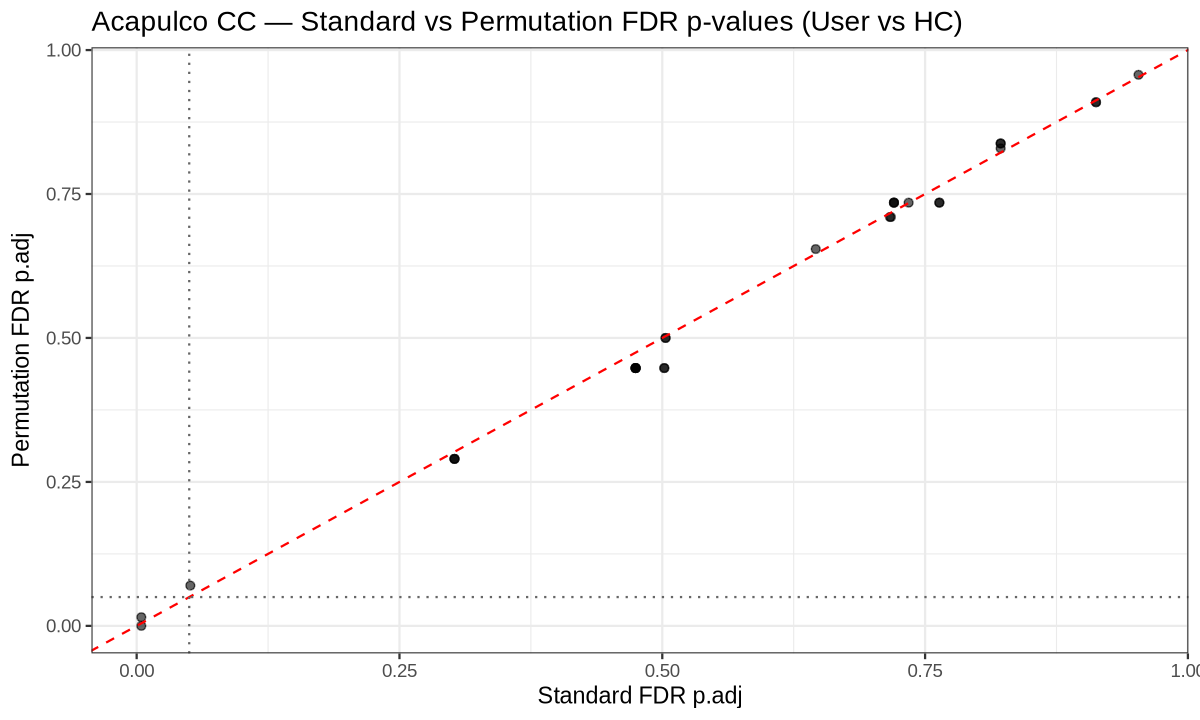

In [35]:
# Correlation of p.adj values between standard and permutation approaches (Acapulco CC)
acapulco_cc_comparison <- p_values_Acapulco_CC_user_vs_control %>%
    select(region, p.adj) %>%
    rename(p.adj_standard = p.adj) %>%
    left_join(
        p_values_Acapulco_CC_user_vs_control_perm %>%
            select(region, p.adj) %>%
            rename(p.adj_perm = p.adj),
        by = "region"
    )

cor_val <- cor(acapulco_cc_comparison$p.adj_standard,
               acapulco_cc_comparison$p.adj_perm,
               use = "complete.obs", method = "spearman")

cat(sprintf("\nAcapulco CC — Spearman correlation (standard vs permutation p.adj): r = %.3f\n",
            cor_val))

acapulco_cc_comparison %>%
    ggplot(aes(x = p.adj_standard, y = p.adj_perm)) +
    geom_point(alpha = 0.6, size = 2) +
    geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "red") +
    geom_hline(yintercept = 0.05, linetype = "dotted", colour = "grey40") +
    geom_vline(xintercept = 0.05, linetype = "dotted", colour = "grey40") +
    labs(title = "Acapulco CC — Standard vs Permutation FDR p-values (User vs HC)",
         x = "Standard FDR p.adj",
         y = "Permutation FDR p.adj") +
    theme_bw(base_size = 14)

MDTB CC — Spearman correlation (standard vs permutation p.adj): r = 0.966


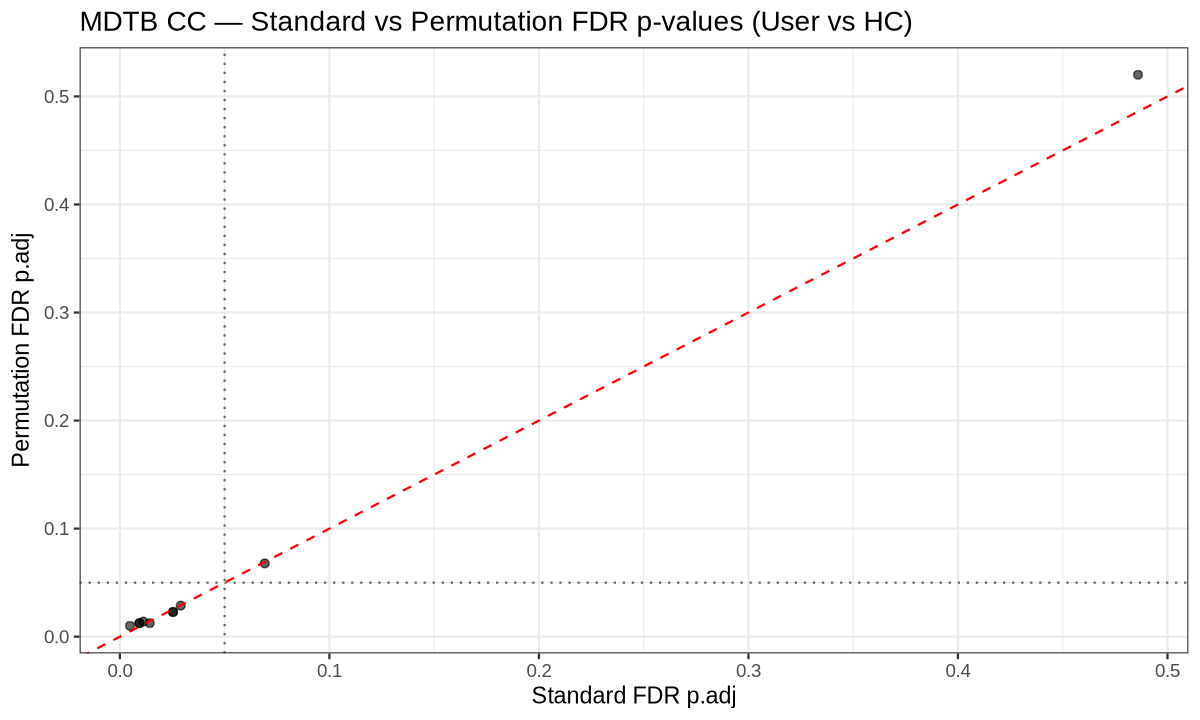

In [36]:
# Same correlation for MDTB CC
mdtb_cc_comparison <- p_values_MDTB_CC_user_vs_control %>%
    select(region, p.adj) %>%
    rename(p.adj_standard = p.adj) %>%
    left_join(
        p_values_MDTB_CC_user_vs_control_perm %>%
            select(region, p.adj) %>%
            rename(p.adj_perm = p.adj),
        by = "region"
    )

cor_val_mdtb <- cor(mdtb_cc_comparison$p.adj_standard,
                    mdtb_cc_comparison$p.adj_perm,
                    use = "complete.obs", method = "spearman")

cat(sprintf("MDTB CC — Spearman correlation (standard vs permutation p.adj): r = %.3f\n",
            cor_val_mdtb))

mdtb_cc_comparison %>%
    ggplot(aes(x = p.adj_standard, y = p.adj_perm)) +
    geom_point(alpha = 0.6, size = 2) +
    geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "red") +
    geom_hline(yintercept = 0.05, linetype = "dotted", colour = "grey40") +
    geom_vline(xintercept = 0.05, linetype = "dotted", colour = "grey40") +
    labs(title = "MDTB CC — Standard vs Permutation FDR p-values (User vs HC)",
         x = "Standard FDR p.adj",
         y = "Permutation FDR p.adj") +
    theme_bw(base_size = 14)

---
# **Part 4 — Update sanity-check RData with permutation results**

Overwrite the existing sanity-check RData files so that downstream scripts  
(especially `07_Figures.ipynb`) automatically use the **permutation-based** p-values  
instead of the standard FDR ones.

> **Note:** The variable names are kept identical (`p_values_Acapulco_CC_user_vs_control`, etc.)  
> to maintain backwards compatibility with `07_Figures.ipynb`.

In [37]:
# Re-assign to names expected by 07_Figures.ipynb
p_values_Acapulco_CC_user_vs_control      <- p_values_Acapulco_CC_user_vs_control_perm
p_values_Acapulco_CC_substance_vs_control <- p_values_Acapulco_CC_substance_vs_control_perm
p_values_Acapulco_AI_user_vs_control      <- p_values_Acapulco_AI_user_vs_control_perm
p_values_Acapulco_AI_substance_vs_control <- p_values_Acapulco_AI_substance_vs_control_perm

save(
    p_values_Acapulco_CC_user_vs_control,
    p_values_Acapulco_CC_substance_vs_control,
    p_values_Acapulco_AI_user_vs_control,
    p_values_Acapulco_AI_substance_vs_control,
    file = "Statistics/Sanity_check/Acapulco/Acapulco_sanity_check_statistics.RData"
)
cat("Acapulco_sanity_check_statistics.RData updated with permutation p-values.\n")

# Export updated CSVs (overwrite)
purrr::iwalk(
    list(
        Acapulco_CC_user_vs_control      = p_values_Acapulco_CC_user_vs_control,
        Acapulco_CC_substance_vs_control = p_values_Acapulco_CC_substance_vs_control,
        Acapulco_AI_user_vs_control      = p_values_Acapulco_AI_user_vs_control,
        Acapulco_AI_substance_vs_control = p_values_Acapulco_AI_substance_vs_control
    ),
    ~ write_csv(.x, file.path("Statistics", "Sanity_check", "Acapulco",
                               paste0(.y, ".csv")))
)
cat("Acapulco CSVs updated.\n")

Acapulco_sanity_check_statistics.RData updated with permutation p-values.
Acapulco CSVs updated.


In [38]:
# Re-assign to names expected by 07_Figures.ipynb
p_values_MDTB_CC_user_vs_control      <- p_values_MDTB_CC_user_vs_control_perm
p_values_MDTB_CC_substance_vs_control <- p_values_MDTB_CC_substance_vs_control_perm
p_values_MDTB_AI_user_vs_control      <- p_values_MDTB_AI_user_vs_control_perm
p_values_MDTB_AI_substance_vs_control <- p_values_MDTB_AI_substance_vs_control_perm

save(
    p_values_MDTB_CC_user_vs_control,
    p_values_MDTB_CC_substance_vs_control,
    p_values_MDTB_AI_user_vs_control,
    p_values_MDTB_AI_substance_vs_control,
    file = "Statistics/Sanity_check/MDTB/MDTB_sanity_check_statistics.RData"
)
cat("MDTB_sanity_check_statistics.RData updated with permutation p-values.\n")

# Export updated CSVs (overwrite)
purrr::iwalk(
    list(
        MDTB_CC_user_vs_control      = p_values_MDTB_CC_user_vs_control,
        MDTB_CC_substance_vs_control = p_values_MDTB_CC_substance_vs_control,
        MDTB_AI_user_vs_control      = p_values_MDTB_AI_user_vs_control,
        MDTB_AI_substance_vs_control = p_values_MDTB_AI_substance_vs_control
    ),
    ~ write_csv(.x, file.path("Statistics", "Sanity_check", "MDTB",
                               paste0(.y, ".csv")))
)
cat("MDTB CSVs updated.\n")

MDTB_sanity_check_statistics.RData updated with permutation p-values.
MDTB CSVs updated.
